# Exploratory Data Analysis - sabana_agent_rl

**Goal:** Entender la data, hacer algunas visuales importantes antes de diseñar el estado y el reward.

**Anti-leakage rule:** Este notebook hace solamente un análisis de los periodos de **train + validation**.

El periodo de held-out se excluyó para que ninguna decisión, de features, windows y reward sea influenciada por data por la que el agente será juzgado.

Correr con `jupyter notebook notebooks/eda.ipynb`, después de `python -m src.data`.

In [3]:
import os, sys
os.chdir("..") if os.path.basename(os.getcwd()) == "notebooks" else None
sys.path.append(".")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import FEATURES, add_features, check_no_lookahead, load_config, load_prices

cfg = load_config()
raw = load_prices(cfg["data"]["path"])
f = cfg["features"]
df = add_features(raw, f["short_window"], f["long_window"], f["rsi_window"])

dev = df.loc[: cfg["data"]["val_end"]]          # train + validation only
train_end = pd.Timestamp(cfg["data"]["train_end"])
print(f"Bars analysed: {len(dev)}  ({dev.index[0]} -> {dev.index[-1]})")
dev[["open", "high", "low", "close", "volume"]].describe().round(2)

Bars analysed: 52375  (2019-01-08 05:00:00 -> 2024-12-31 23:00:00)


,open,high,low,close,volume
count,52375.00,52375.00,52375.00,52375.00,52375.00
mean,31563.41,31705.08,31414.18,31565.12,3233.42
std,22080.13,22173.54,21982.07,22081.47,4433.35
min,3366.63,3386.97,3349.92,3366.41,0.00
25%,10612.72,10666.37,10566.62,10614.54,1015.05
50%,27411.54,27496.74,27315.55,27412.14,1788.38
75%,46586.43,46829.81,46296.70,46588.50,3511.19
max,108258.38,108353.00,107130.00,108258.39,137207.19


## 1. Evolución del precio

La escala logarítmica permite comparar los movimientos porcentuales a lo largo de los años. La línea discontinua marca el límite entre los períodos de entrenamiento y validación.

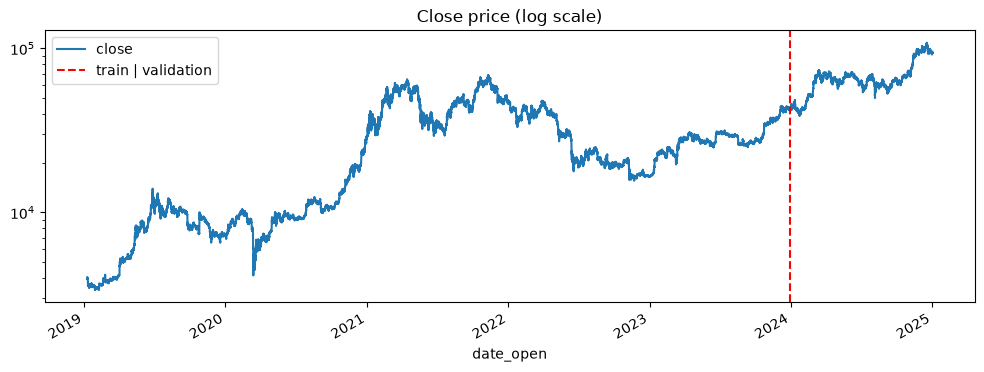

In [4]:
ax = dev["close"].plot(figsize=(12, 4), logy=True, title="Close price (log scale)")
ax.axvline(train_end, color="red", ls="--", label="train | validation")
ax.legend(); plt.show()

## 2. Distribución de los retornos

Retornos logarítmicos por hora. Se comparan con una distribución normal, donde las colas pesadas indican movimientos poco frecuentes, pero de gran magnitud, que son relevantes para el drawdown o las caídas máximas del portafolio.

mean=0.00006  std=0.0071  skew=-0.83  excess kurtosis=48.4
lag-1 autocorrelation=-0.018  (close to 0 -> past returns barely predict the next one)


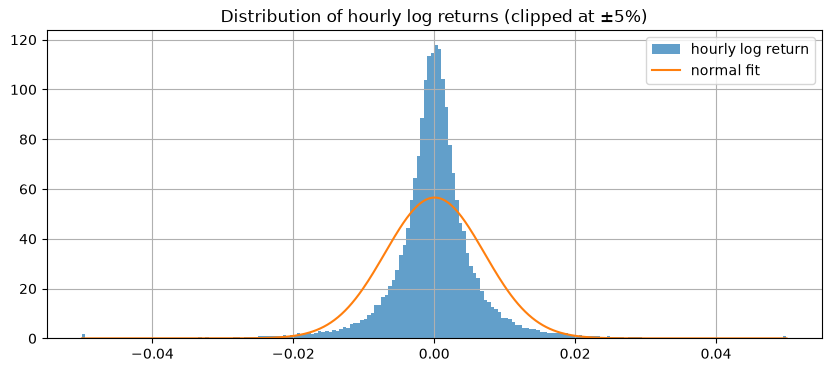

In [ ]:
r = np.log(dev["close"]).diff().dropna()
print(f"mean={r.mean():.5f}  std={r.std():.4f}  skew={r.skew():.2f}  excess kurtosis={r.kurt():.1f}")
print(f"lag-1 autocorrelation={r.autocorr(1):.3f}  (close to 0 -> past returns barely predict the next one)")

fig, ax = plt.subplots(figsize=(10, 4))
r.clip(-0.05, 0.05).hist(bins=200, density=True, ax=ax, alpha=0.7, label="hourly log return")
x = np.linspace(-0.05, 0.05, 400)
ax.plot(x, np.exp(-(x - r.mean())**2 / (2 * r.std()**2)) / (r.std() * np.sqrt(2 * np.pi)), label="normal fit")
ax.set_title("Distribution of hourly log returns (clipped at +-5%)"); ax.legend(); plt.show()

## 3. Regímenes de volatilidad

Volatilidad móvil de 7 días, anualizada. Dado que el mercado de criptomonedas opera las 24 horas del día, los 7 días de la semana, se utilizan 24 × 365 períodos horarios por año.

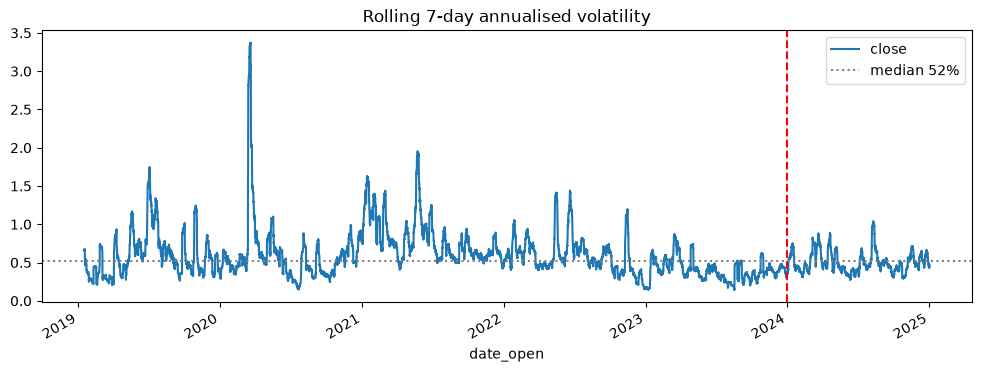

Top-5% volatility hours fall in: {2019: 634, 2020: 371, 2021: 1194, 2022: 412}


In [6]:
vol = r.rolling(168).std() * np.sqrt(24 * 365)
ax = vol.plot(figsize=(12, 4), title="Rolling 7-day annualised volatility")
ax.axhline(vol.median(), color="gray", ls=":", label=f"median {vol.median():.0%}")
ax.axvline(train_end, color="red", ls="--"); ax.legend(); plt.show()
print("Top-5% volatility hours fall in:", vol[vol > vol.quantile(0.95)].index.year.value_counts().sort_index().to_dict())

## 4. Tendencias y drawdowns del activo

La curva de caídas (underwater curve) muestra cuánto se encuentra el precio por debajo de su máximo histórico anterior. Esta es la caída que experimenta una estrategia de comprar y mantener (buy and hold).

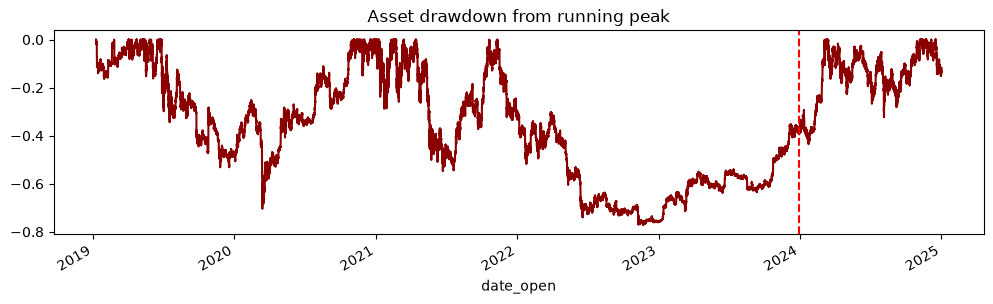

Max drawdown in train+val: -77.2% on 2022-11-21 21:00:00
Yearly returns: {2020: '302%', 2021: '60%', 2022: '-64%', 2023: '156%', 2024: '121%'}


In [7]:
dd = dev["close"] / dev["close"].cummax() - 1
ax = dd.plot(figsize=(12, 3), title="Asset drawdown from running peak", color="darkred")
ax.axvline(train_end, color="red", ls="--"); plt.show()
print(f"Max drawdown in train+val: {dd.min():.1%} on {dd.idxmin()}")
yearly = dev["close"].resample("YE").last().pct_change()
yearly.index = yearly.index.year
print("Yearly returns:", yearly.dropna().map(lambda v: f"{v:.0%}").to_dict())

## 5. Volumen

El volumen se muestra como información de contexto, pero no se utiliza como variable de entrada del agente. El volumen de un único exchange no es estacionario debido a cambios estructurales, como variaciones en su participación de mercado o promociones en las comisiones. Por esta razón, resulta difícil comparar directamente su nivel entre diferentes años.

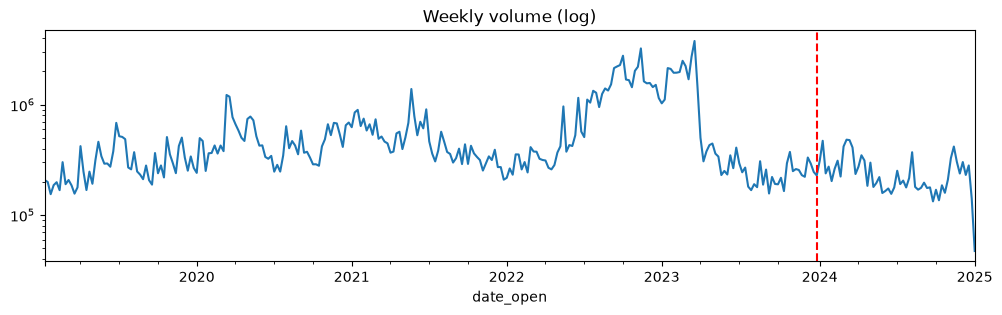

In [8]:
ax = dev["volume"].resample("W").sum().plot(figsize=(12, 3), logy=True, title="Weekly volume (log)")
ax.axvline(train_end, color="red", ls="--"); plt.show()

## 6. Indicadores seleccionados

Variables originales, sin normalizar, correspondientes a los últimos 60 días del conjunto de entrenamiento, junto con su matriz de correlación. Las variables con una correlación elevada aportan poca información adicional al agente.

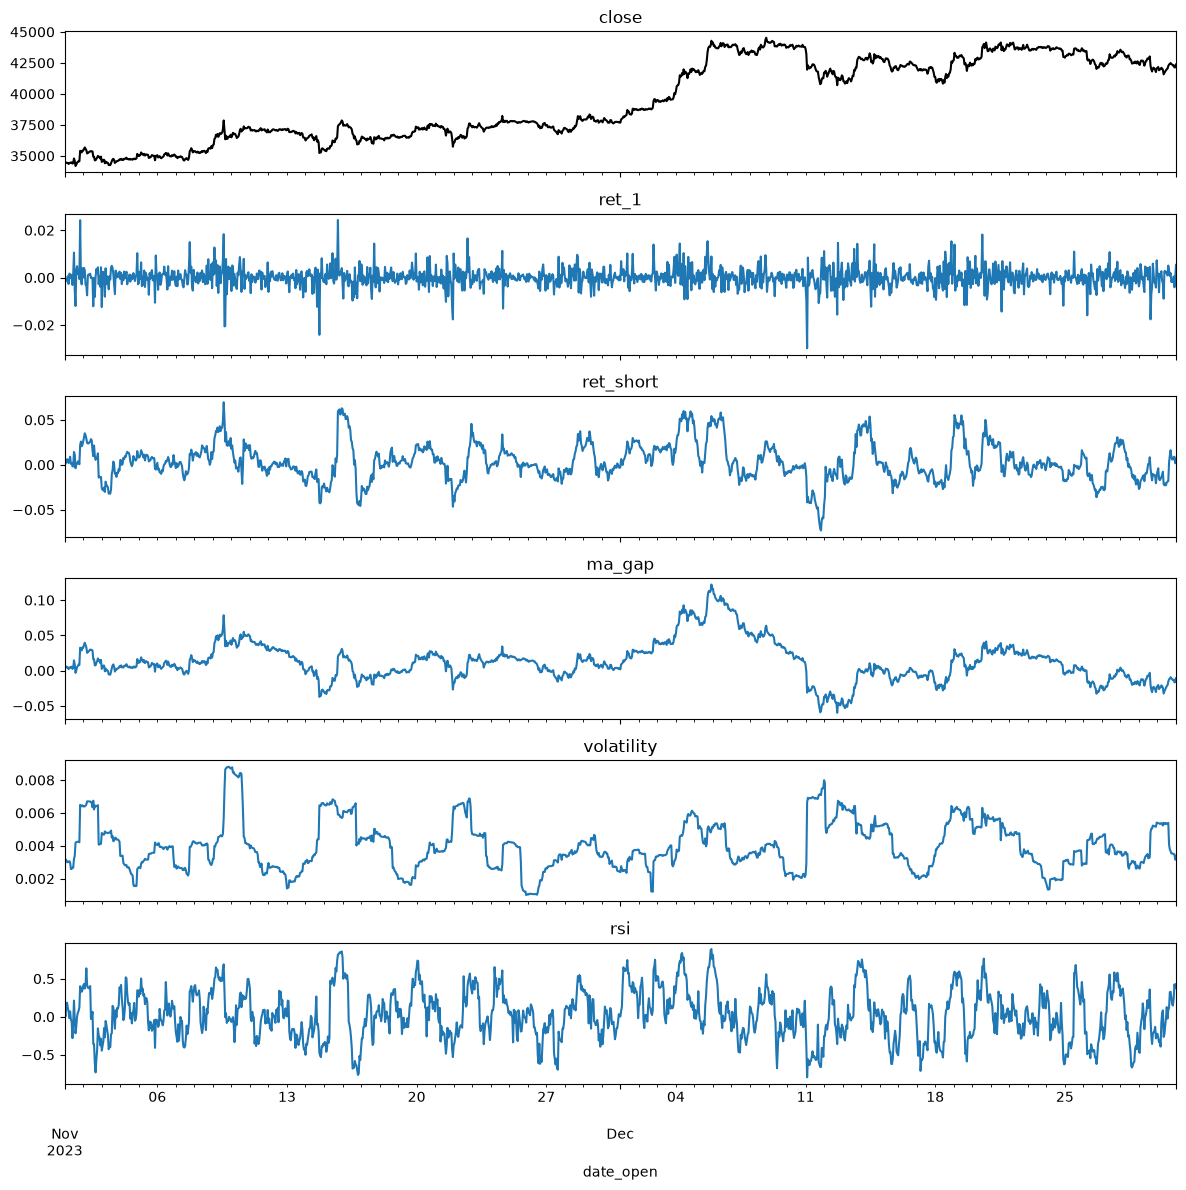

,ret_1,ret_short,ma_gap,volatility,rsi
ret_1,1.00,0.21,0.13,-0.00,0.25
ret_short,0.21,1.00,0.61,-0.10,0.64
ma_gap,0.13,0.61,1.00,-0.15,0.40
volatility,-0.00,-0.10,-0.15,1.00,-0.02
rsi,0.25,0.64,0.40,-0.02,1.00


In [9]:
window = dev.loc[train_end - pd.Timedelta(days=60): train_end]
fig, axes = plt.subplots(len(FEATURES) + 1, 1, figsize=(12, 12), sharex=True)
window["close"].plot(ax=axes[0], title="close", color="black")
for ax, col in zip(axes[1:], FEATURES):
    window[col].plot(ax=ax, title=col)
plt.tight_layout(); plt.show()
dev[FEATURES].corr().round(2)

## 7. No estacionariedad: entrenamiento frente a validación

Si las distribuciones de las variables cambian entre períodos, es posible que una política aprendida durante el entrenamiento no se generalice adecuadamente al período de validación. La normalización utiliza únicamente las estadísticas del conjunto de entrenamiento, por lo que es esperable que las variables de validación presenten cierto desplazamiento. Esto representa una evaluación metodológicamente correcta y transparente.

In [ ]:

parts = {"train": dev.loc[:train_end], "val": dev.loc[train_end + pd.Timedelta(hours=1):]}
pd.concat({k: v[FEATURES].agg(["mean", "std"]) for k, v in parts.items()}).round(4)

ret_1  ret_short  ma_gap  volatility     rsi
train mean  0.0001     0.0013  0.0053      0.0060  0.0191
      std   0.0073     0.0354  0.0534      0.0042  0.3296
val   mean  0.0001     0.0022  0.0080      0.0051  0.0307
      std   0.0056     0.0267  0.0410      0.0024  0.3257

## 8. Auditoría de lookahead

Las variables se recalculan utilizando los datos truncados en fechas seleccionadas aleatoriamente. Los valores obtenidos en cada punto de corte deben ser idénticos a los calculados utilizando la serie original completa. Esto permite verificar que las variables no incorporen información futura.

In [11]:
check_no_lookahead(raw, cfg)

Lookahead check passed (5 random cut points).


## 9. Train - Val - Test

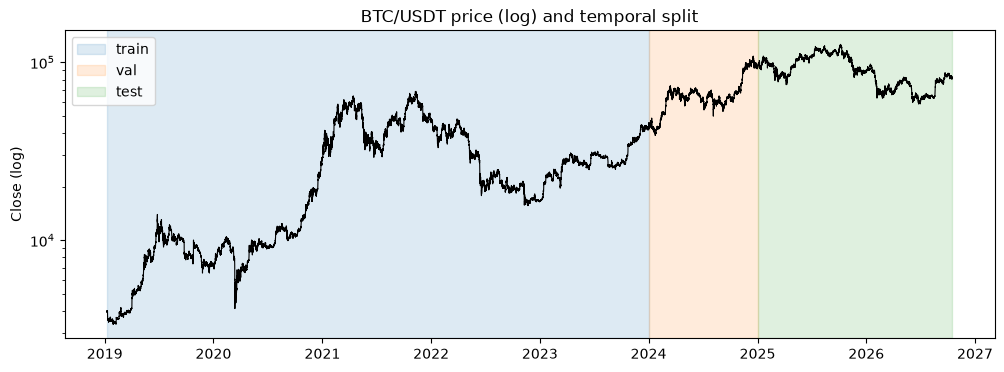

,split,start,end,bars
0,train,2019-01-08 05:00:00,2023-12-31 23:00:00,43591
1,val,2024-01-01 00:00:00,2024-12-31 23:00:00,8784
2,test,2025-01-01 00:00:00,2026-10-17 01:00:00,15698


In [12]:
import pandas as pd

# Temporal split: boundaries taken from the config (single source of truth)
train_end = pd.Timestamp(cfg["data"]["train_end"]) + pd.Timedelta(days=1)  # end of that day
val_end = pd.Timestamp(cfg["data"]["val_end"]) + pd.Timedelta(days=1)

splits = {
    "train": df[df.index < train_end],
    "val":   df[(df.index >= train_end) & (df.index < val_end)],
    "test":  df[df.index >= val_end],
}
colors = {"train": "tab:blue", "val": "tab:orange", "test": "tab:green"}

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index, df["close"], color="black", lw=0.8)
ax.set_yscale("log")
for name, part in splits.items():
    ax.axvspan(part.index[0], part.index[-1], color=colors[name], alpha=0.15, label=name)
ax.set_title(f"{cfg['data']['symbol']} price (log) and temporal split")
ax.set_ylabel("Close (log)")
ax.legend(loc="upper left")
plt.show()

# Size of each split (no statistics computed on test)
pd.DataFrame([
    {"split": name, "start": part.index[0], "end": part.index[-1], "bars": len(part)}
    for name, part in splits.items()
])

## 10. Conclusiones
- **Retornos:** Vemos una media de aprox 0, desviación de 0.71 % por hora, asimetría negativa (-0.83) y colas muy pesadas (curtosis en exceso de 48). La autocorrelación de un periodo es -0.018. Esto nos dice que la predictibilidad de corto plazo es mínima y un costo de 10 bps puede anular cualquier ventaja. Por eso los indicadores se recortan a +-5 desviaciones.
- **Volatilidad:** hay regímenes claros. Todas las horas del 5 % más volátil están en 2019-2022 y ninguna en 2023-2024. Esto justifica incluir `volatility` en el estado.
- **Tendencias y caídas:** máximo drawdown del activo de -77 % (nov-2022), con años muy distintos (2022: -64 %; 2024: +121 %). Esto motiva la recompensa v2 con penalización por drawdown.
- **Volumen:** no es estacionario y hay barras con volumen 0, así que no se usa como indicador.
- **Indicadores:** la correlación máxima es 0.64 (`ret_short`–`rsi`), así que ninguno es redundante. `volatility` es casi independiente de los demás.
- **No estacionariedad:** validación (2024) tiene menor volatilidad (0.0051 vs 0.0060) y más tendencia alcista (`ma_gap` 0.008 vs 0.005) que train. La selección por validación favorecerá políticas muy invertidas, y comprar y mantener será un baseline difícil de superar.
- **Lookahead:** la auditoría pasó (5 cortes aleatorios). Los indicadores solo usan información disponible hasta t.